# Image Thresholding
- Canny Edge and Contour Detection
- Adaptive Mean Thresholding
- Adaptive Gaussian Thresholding
- Otsu's Thresholding

In [ ]:
# Necessary Imports

import cv2
import numpy as np
import matplotlib.pyplot as plt

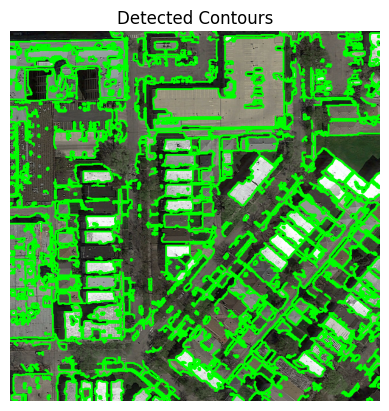

In [ ]:
# Canny Edge+Contour Detection

image = cv2.imread('topdown_image.png')
if image is None:
    print("Error: Image not found.")
else:
    # Preprocessing
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Edge Detection
    edges = cv2.Canny(blurred, 100, 200)

    # Find Contours
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Draw results on a copy
    output = image.copy()
    cv2.drawContours(output, contours, -1, (0, 255, 0), 2)

    # Display using Matplotlib (Convert BGR to RGB)
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title('Detected Contours')
    plt.axis('off') # Hide axes
    plt.show()


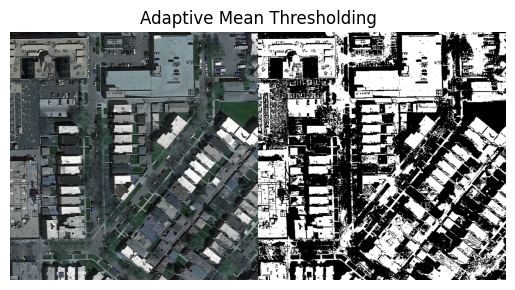

In [ ]:
# Adaptive Mean Thresholding

thresh_mean = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    199, 5
)

combined = cv2.hconcat([image, cv2.cvtColor(thresh_mean, cv2.COLOR_GRAY2BGR)])

plt.imshow(combined)
plt.title('Adaptive Mean Thresholding')
plt.axis('off') # Hide axes
plt.show()

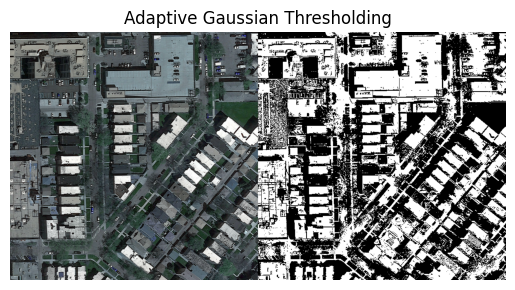

In [ ]:
# Adaptive Gaussian Thresholding

thresh_gauss = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    199, 5
)

combined = cv2.hconcat([image, cv2.cvtColor(thresh_gauss, cv2.COLOR_GRAY2BGR)])

plt.imshow(combined)
plt.title('Adaptive Gaussian Thresholding')
plt.axis('off') # Hide axes
plt.show()

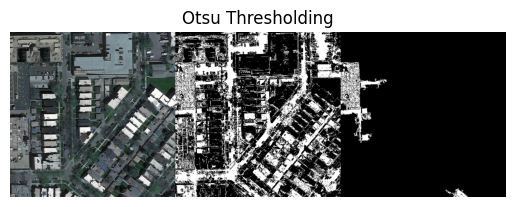

In [ ]:
# Apply Otsu's thresholding

ret, thresh_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
v_mask = cv2.inRange(v, 60, 130)  
road_candidates = cv2.bitwise_and(thresh_s, v_mask)

# Connected component analysis
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(road_candidates)

# Filter by shape - roads are elongated
filtered = np.zeros_like(road_candidates)
for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    aspect_ratio = max(w,h) / (min(w,h) + 1e-5)
    
    # Roads are elongated (high aspect ratio) or large connected networks
    if aspect_ratio > 2.0 and area > 500:
        filtered[labels == i] = 255

combined = cv2.hconcat([image,cv2.cvtColor(road_candidates, cv2.COLOR_GRAY2BGR),  cv2.cvtColor(filtered, cv2.COLOR_GRAY2BGR)])

plt.imshow(combined)
plt.title('Otsu Thresholding')
plt.axis('off') # Hide axes
plt.show()

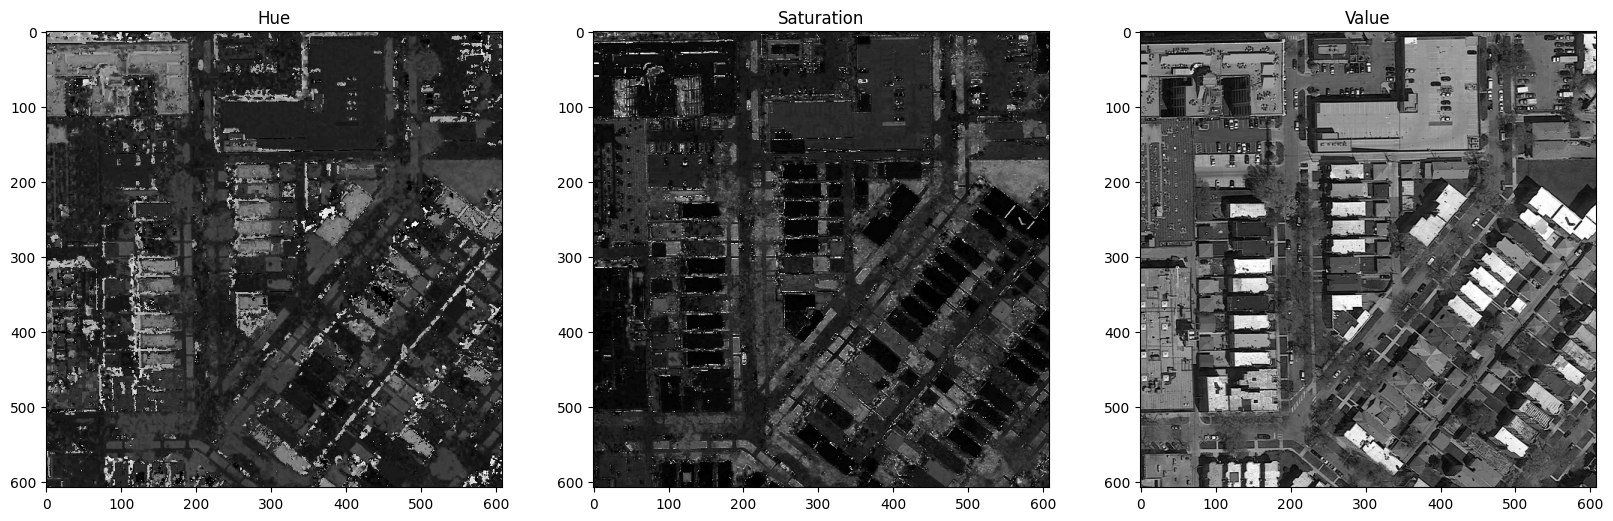

In [ ]:
# Display H vs S vs V channels

hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].imshow(h, cmap='gray')
axes[0].set_title('Hue')
axes[1].imshow(s, cmap='gray')
axes[1].set_title('Saturation')
axes[2].imshow(v, cmap='gray')
axes[2].set_title('Value')
plt.show()

## Results:
These classical methods (including sliders) failed due to constant need to adjust values per image, failing to generalize.  
Switched to a ML approaches like RF and UNet(CNN) for better generalization